# 03_2. M1 — CatBoost / M1 — CatBoost

**EN.** M1 is the main single model of the thesis: gradient boosting of decision trees (CatBoost) for Y1 (early default) on the 18 selected features. Each new tree corrects the errors of the previous ones; categorical features are encoded by ordered target statistics. This notebook shows:

1. **Tuning**: Optuna, 40 trials per study — the main set (18 features) and the two H3 sets (static, 16 features; static + the 7 selected dynamic ones, 23); the metric is the ω-weighted log-loss on validation half A; the number of trees is set by **early stopping** (training stops when the half-A log-loss has not improved for 100 trees). Tuning and the final models were run on a Colab GPU (`notebooks/colab_stage3_catboost.ipynb` with the project scripts `scripts/tune.py` and `scripts/fit_models.py`) and imported; here we read the saved studies and models.
2. **Final models**: with the best parameters, 5 models on 5 **GroupKFold** folds of train (all snapshots of a loan in the same fold). The M1 prediction is the mean logit of the 5 models; each train row also gets an **out-of-fold** prediction from the model that did not see its loan — the input of the hybrid in stage 4.
3. **Variants** with the hyperparameters of M1: without the exposure weight ω (for H4) and three sensitivity variants — linear instead of logarithmic ω, sampling rate of non-events r = 0.1 instead of 0.2, and without the rows of loans prepaid within the 12-month window; separately tuned models on the static and full H3 sets.
4. A **validation preview** (half A, after Platt calibration on half B) and **SHAP** importance. The final numbers are on test (03_6).

**RU.** M1 — основная одиночная модель работы: градиентный бустинг деревьев решений (CatBoost) для Y1 (ранний дефолт) на 18 отобранных признаках. Каждое новое дерево исправляет ошибки предыдущих; категориальные признаки кодируются упорядоченными целевыми статистиками. В ноутбуке:

1. **Подбор гиперпараметров**: Optuna, 40 попыток на подбор — основной набор (18 признаков) и два набора H3 (статический, 16 признаков; статический + 7 отобранных динамических, 23); метрика — взвешенный по ω log-loss на половине A validation; число деревьев задаёт **ранняя остановка** (обучение прекращается, если log-loss на A не улучшался 100 деревьев). Подбор и итоговые модели выполнены на GPU в Colab (`notebooks/colab_stage3_catboost.ipynb` со скриптами проекта `scripts/tune.py` и `scripts/fit_models.py`) и импортированы; здесь читаем сохранённые журналы подбора и модели.
2. **Итоговые модели**: с лучшими параметрами — 5 моделей на 5 фолдах **GroupKFold** по train (все снимки кредита в одном фолде). Прогноз M1 — средний логит 5 моделей; каждая строка train получает ещё и **out-of-fold** прогноз от модели, не видевшей её кредит, — вход гибрида на этапе 4.
3. **Варианты** с гиперпараметрами M1: без веса по ОД ω (для H4) и три варианта чувствительности — линейный ω вместо логарифмического, доля подвыборки кредитов без события r = 0,1 вместо 0,2 и без строк кредитов, досрочно погашенных в 12-месячном окне; отдельно подобранные модели на статическом и полном наборах H3.
4. **Предварительный взгляд на validation** (половина A, после калибровки Платта на половине B) и важность по **SHAP**. Итоговые цифры — на test (03_6).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import gc
import json
import pickle
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

from catboost import CatBoostClassifier
from xai_ews.evaluation.metrics import all_metrics, auc
from xai_ews.models import catboost_model as cb
from xai_ews.models import registry
from xai_ews.models.calibration import Platt
from xai_ews.models.data import load_eval, to_model_frame
from xai_ews.paths import MODELS_DIR, PREDICTIONS_DIR, MODELING_DIR

STUDIES = ["catboost_y1_main", "catboost_y1_h3_static", "catboost_y1_h3_full"]
VARIANTS = ["m1_y1", "m1_y1_noomega", "h3_static_y1", "h3_full_y1", "m1_y1_linear", "m1_y1_r01", "m1_y1_noprepaid"]

### 1. Tuning results / Результаты подбора

**EN.** For each study: the best trial, its parameters, the number of trees chosen by early stopping, log-loss and AUC on half A, and how many of the 40 trials came within 1 % of the best log-loss (a flat optimum means the choice is not fragile).

**RU.** Для каждого подбора: лучшая попытка, её параметры, число деревьев по ранней остановке, log-loss и AUC на половине A, и сколько из 40 попыток оказались в пределах 1 % от лучшего log-loss (плоский оптимум — выбор не хрупкий).

In [2]:
rows, hist = [], {}
for s in STUDIES:
    df = registry.trials_frame(s)
    df = df[df["state"] == "COMPLETE"].sort_values("number")
    df.to_csv(MODELING_DIR / f"tuning_{s}.csv", index=False)
    hist[s] = df
    b = df.loc[df["value"].idxmin()]
    rows.append({"study": s, "trials": len(df), "best_trial": int(b["number"]), "log_loss_A": b["value"],
                 "auc_A": b["user_attrs_auc_A"], "trees": int(b["user_attrs_trees"]),
                 **{k.removeprefix("params_"): b[k] for k in df.columns if k.startswith("params_")},
                 "within_1pct": int((df["value"] <= b["value"] * 1.01).sum()),
                 "hours": df["duration"].sum().total_seconds() / 3600})
tuning = pd.DataFrame(rows).set_index("study")
tuning.to_csv(MODELING_DIR / "tuning_catboost_summary.csv")
tuning

,trials,best_trial,log_loss_A,auc_A,trees,depth,l2_leaf_reg,learning_rate,min_data_in_leaf,subsample,within_1pct,hours
study,,,,,,,,,,,,
catboost_y1_main,40,36,0.0122,0.8632,321,4,3.3148,0.0630,31,0.9278,32,0.0690
catboost_y1_h3_static,40,38,0.0125,0.8486,238,4,1.7985,0.0511,38,0.9754,40,0.0673
catboost_y1_h3_full,40,36,0.0122,0.8632,1047,4,3.5888,0.0291,15,0.9737,30,0.0963


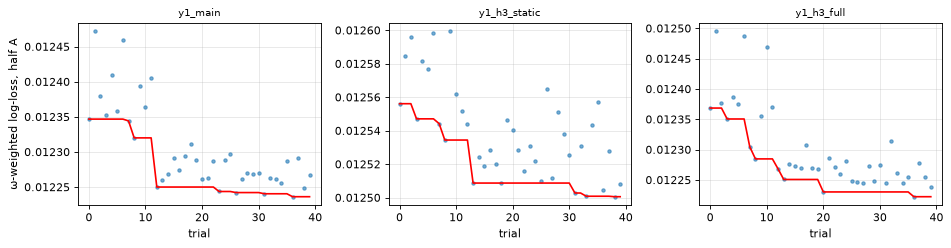

In [3]:
fig, axes = plt.subplots(1, len(STUDIES), figsize=(4 * len(STUDIES), 3.2))
for ax, s in zip(axes, STUDIES):
    df = hist[s]
    ax.plot(df["number"], df["value"], "o", ms=3, alpha=0.6)
    ax.plot(df["number"], df["value"].cummin(), "r-")
    ax.set_title(s.removeprefix("catboost_"), fontsize=9); ax.set_xlabel("trial")
axes[0].set_ylabel("ω-weighted log-loss, half A")
plt.tight_layout(); plt.show()

**EN. How to read.** The optimum is **flat**: 32 of the 40 trials of the main study, 30 of the full H3 study and all 40 of the static one are within 1 % of the best log-loss, and even the worst trial is only 0.8–2.2 % worse. The hyperparameters matter little: the model is limited by the information in the features, not by tuning. **All the best trials sit at depth 4, the lower end of the range 4–10 fixed in the protocol**: without the delinquency features the signal is simple enough for shallow trees, and deeper trees overfit. The range is not changed after the fact; the observation goes to the report. **Main set (M1):** trial 36, 321 trees, learning rate 0.063, L2 3.3, at least 31 rows per leaf, 93 % of the rows per tree; half-A log-loss 0.01224, AUC 0.863. **Full H3 set:** the same AUC 0.863 with a slower learning rate (0.029) and more trees (1,047). **Static H3 set:** 238 trees, AUC 0.849. In the main and full H3 studies the trial with the best log-loss also has the highest half-A AUC. Runtime on the Colab GPU: about 6 s per trial (9 s for the 23 features), 4–6 min per study.

**RU. Как читать.** Оптимум **плоский**: 32 из 40 попыток основного подбора, 30 — полного набора H3 и все 40 — статического находятся в пределах 1 % от лучшего log-loss, и даже худшая попытка хуже лишь на 0,8–2,2 %. Гиперпараметры влияют мало: модель ограничена информацией в признаках, а не настройкой. **Все лучшие попытки — на глубине 4, нижней границе диапазона 4–10 из протокола**: без признаков просрочки сигнал достаточно простой для неглубоких деревьев, а глубокие переобучаются. Диапазон задним числом не меняется, наблюдение идёт в отчёт. **Основной набор (M1):** попытка 36, 321 дерево, скорость обучения 0,063, L2 3,3, не меньше 31 строки в листе, 93 % строк на дерево; log-loss на половине A 0,01224, AUC 0,863. **Полный набор H3:** тот же AUC 0,863 при меньшей скорости обучения (0,029) и большем числе деревьев (1 047). **Статический набор H3:** 238 деревьев, AUC 0,849. В основном и полном подборах попытка с лучшим log-loss даёт и самый высокий AUC на половине A. Время на GPU в Colab — около 6 с на попытку (9 с на 23 признаках), 4–6 мин на подбор.

### 2. Final fold models and out-of-fold predictions / Итоговые фолдовые модели и out-of-fold прогнозы

**EN.** Every variant: task, label, exposure weight, r, number of trees, train rows and events. The out-of-fold AUC on train is compared with the half-A AUC: if they are close, the fold models do not overfit their own loans, and the out-of-fold predictions are a fair input for the hybrid.

**RU.** Для каждого варианта: задача, метка, вес по ОД, r, число деревьев, строки и события train. Out-of-fold AUC на train сравнивается с AUC на половине A: если они близки, фолдовые модели не переобучаются на своих кредитах, и out-of-fold прогнозы — честный вход для гибрида.

In [4]:
info = []
for v in VARIANTS:
    m = registry.meta(v)
    oof = pl.read_parquet(MODELS_DIR / v / "oof.parquet")
    info.append({"variant": v, "task": m["task"], "label": m["label"], "omega": m["omega"], "r": m["r"],
                 "drop_prepaid": m["drop_prepaid"], "features": len(m["features"]), "trees": m["trees"],
                 "train_rows": m["train_rows"], "train_events": m["train_events"],
                 "oof_auc_train": auc(oof[m["label"]].to_numpy(), oof["logit"].to_numpy(),
                                      oof["sample_weight"].to_numpy())})
info = pd.DataFrame(info).set_index("variant")
info

,task,label,omega,r,drop_prepaid,features,trees,train_rows,train_events,oof_auc_train
variant,,,,,,,,,,
m1_y1,y1,y1,log,0.2000,False,18,321,2294292,14062,0.8565
m1_y1_noomega,y1,y1,NaN,0.2000,False,18,321,2294292,14062,0.8552
h3_static_y1,y1,y1,log,0.2000,False,16,238,2294292,14062,0.8441
h3_full_y1,y1,y1,log,0.2000,False,23,1047,2294292,14062,0.8575
m1_y1_linear,y1,y1,linear,0.2000,False,18,321,2294292,14062,0.8550
m1_y1_r01,y1,y1,log,0.1000,False,18,321,1155111,14062,0.8559
m1_y1_noprepaid,y1,y1,log,0.2000,True,18,321,2080094,12978,0.8631


### 3. Validation preview / Предварительный взгляд на validation

**EN.** Fold-average logits on all validation rows (kept by the disaster rule); Platt calibration on half B; metrics on half A. Predictions are saved for 03_4 (EL, lead time) and for stage 4. The OOF column of the previous table is repeated for comparison.

**RU.** Средние логиты фолдовых моделей на всех строках validation (оставшихся после правила бедствий); калибровка Платта на половине B; метрики на половине A. Прогнозы сохраняются для 03_4 (EL, lead time) и для этапа 4. Для сравнения повторена колонка OOF из предыдущей таблицы.

In [5]:
val_rows, cal = [], {}
cache = {}
for v in VARIANTS:
    m = registry.meta(v)
    label = m["label"]
    f_pred = PREDICTIONS_DIR / f"{v}_validation.parquet"
    if f_pred.exists():
        p = pl.read_parquet(f_pred)
    else:
        va = load_eval("validation", label, m["features"], m["categorical"])
        p = va.select("loan_identifier", "m", label, "half", "upb", "omega").with_columns(
            pl.Series("logit", registry.predict(v, va)))
        p.write_parquet(f_pred)
        del va; gc.collect()
    a, b = p.filter(pl.col("half") == "A"), p.filter(pl.col("half") == "B")
    cal[v] = Platt().fit(b["logit"].to_numpy(), b[label].to_numpy())
    val_rows.append({"variant": v, **all_metrics(a[label].to_numpy(), cal[v].predict(a["logit"].to_numpy())),
                     "platt_a": cal[v].a, "platt_b": cal[v].b, "oof_auc_train": info.loc[v, "oof_auc_train"]})
val = pd.DataFrame(val_rows).set_index("variant")
val.to_csv(MODELING_DIR / "m1_validation_metrics.csv")
val[["n", "events", "auc", "gini", "ks", "pr_auc", "brier", "ece", "cal_slope", "cal_intercept", "platt_b", "oof_auc_train"]]

,n,events,auc,gini,ks,pr_auc,brier,ece,cal_slope,cal_intercept,platt_b,oof_auc_train
variant,,,,,,,,,,,,
m1_y1,853029,1695,0.8629,0.7259,0.5668,0.0156,0.0020,0.0001,1.0503,-0.0077,0.9750,0.8565
m1_y1_noomega,853029,1695,0.8635,0.7271,0.5678,0.0154,0.0020,0.0001,1.0508,-0.0075,0.9732,0.8552
h3_static_y1,853029,1695,0.8491,0.6982,0.5508,0.0114,0.0020,0.0002,1.0690,-0.0070,0.9859,0.8441
h3_full_y1,853029,1695,0.8630,0.7259,0.5691,0.0159,0.0020,0.0001,1.0506,-0.0084,0.9695,0.8575
m1_y1_linear,853029,1695,0.8614,0.7229,0.5721,0.0153,0.0020,0.0001,1.0404,-0.0072,0.9544,0.8550
m1_y1_r01,853029,1695,0.8615,0.7229,0.5650,0.0146,0.0020,0.0001,1.0336,-0.0107,0.9497,0.8559
m1_y1_noprepaid,853029,1695,0.8612,0.7225,0.5674,0.0153,0.0020,0.0001,1.0420,-0.0069,0.9531,0.8631


**EN. How to read.** **M1:** AUC 0.863 (Gini 0.73), KS 0.57, PR-AUC 0.016 against 0.0020 for a random order (8 times more), Brier 0.0020. Calibration on half A after Platt: slope 1.05, intercept −0.008, mean PD 0.200 % against an event rate of 0.199 %, ECE 0.0001 (7 % of the event rate). The Platt coefficients are a = 0.004 and b = 0.975: the raw weighted logits of CatBoost are already on the right scale, unlike B0, whose level had to be raised (03_1). A slope of 1.05 means the calibrated PDs are a touch too cautious at the extremes; the difference is small. Compared with B0 on the same half A, M1 gains 0.011 AUC (0.852 → 0.863) and PR-AUC rises from 0.012 to 0.016. Out-of-fold AUC on train (0.856) is close to the half-A AUC: the fold models do not overfit their own loans, and the OOF predictions are a fair input for stage 4. **Variants:** without ω the AUC is the same (0.8635 vs 0.8629) — H4 is about which large loans reach the alert list, not about AUC; linear ω, r = 0.1 and the model without prepaid rows give 0.861–0.862, so the results do not depend on these choices; all variants are calibrated equally well (slope 1.03–1.07). **H3 preview:** static set 0.849 → full set 0.863 (+0.014; PR-AUC 0.011 → 0.016), close to stage 2 (+0.013). The full H3 model is level with M1 (0.8630 vs 0.8629): adding the geography, term and LTV at origination to the 18 features gives nothing. The formal test of H3 (DeLong, bootstrap, lead time) is on test.

**RU. Как читать.** **M1:** AUC 0,863 (Gini 0,73), KS 0,57, PR-AUC 0,016 против 0,0020 у случайного порядка (в 8 раз больше), Brier 0,0020. Калибровка на половине A после Платта: slope 1,05, intercept −0,008, средняя PD 0,200 % при доле событий 0,199 %, ECE 0,0001 (7 % доли событий). Коэффициенты Платта a = 0,004 и b = 0,975: сырые взвешенные логиты CatBoost уже в нужной шкале, в отличие от B0, у которой уровень пришлось поднимать (03_1). Slope 1,05 означает, что откалиброванные PD на краях чуть осторожнее, чем нужно; разница мала. По сравнению с B0 на той же половине A M1 выигрывает 0,011 AUC (0,852 → 0,863), а PR-AUC растёт с 0,012 до 0,016. Out-of-fold AUC на train (0,856) близок к AUC на половине A: фолдовые модели не переобучаются на своих кредитах, и OOF-прогнозы — честный вход для этапа 4. **Варианты:** без ω AUC тот же (0,8635 против 0,8629) — H4 о том, какие крупные кредиты попадают в список тревоги, а не об AUC; линейный ω, r = 0,1 и модель без досрочно погашенных дают 0,861–0,862, то есть результаты от этих решений не зависят; все варианты откалиброваны одинаково хорошо (slope 1,03–1,07). **Предварительно по H3:** статический набор 0,849 → полный 0,863 (+0,014; PR-AUC 0,011 → 0,016), близко к этапу 2 (+0,013). Полная модель H3 на уровне M1 (0,8630 против 0,8629): география, срок и LTV при выдаче ничего не добавляют к 18 признакам. Формальная проверка H3 (DeLong, bootstrap, lead time) — на test.

### 4. SHAP importance / Важность по SHAP

**EN.** **SHAP** splits a model's logit for one loan into additive contributions of its features (TreeSHAP for trees, on the raw logit scale). The mean |SHAP| over loans = how much a feature moves the prediction on average; the table shows each feature's share of the total. The SHAP of the fold average is the average of the 5 fold models' SHAP (SHAP is additive). Sample: 30,000 rows of half A — all 1,695 events and a random draw of non-events (so events are 5.7 % of the sample instead of 0.20 %).

**RU.** **SHAP** раскладывает логит модели для одного кредита на слагаемые-вклады признаков (TreeSHAP для деревьев, в шкале сырых логитов). Среднее |SHAP| по кредитам — насколько признак в среднем сдвигает прогноз; в таблице — доля каждого признака в сумме. SHAP среднего фолдовых моделей — среднее их SHAP (SHAP аддитивен). Выборка — 30 000 строк половины A: все 1 695 событий и случайная выборка кредитов без события (поэтому событий в выборке 5,7 %, а не 0,20 %).

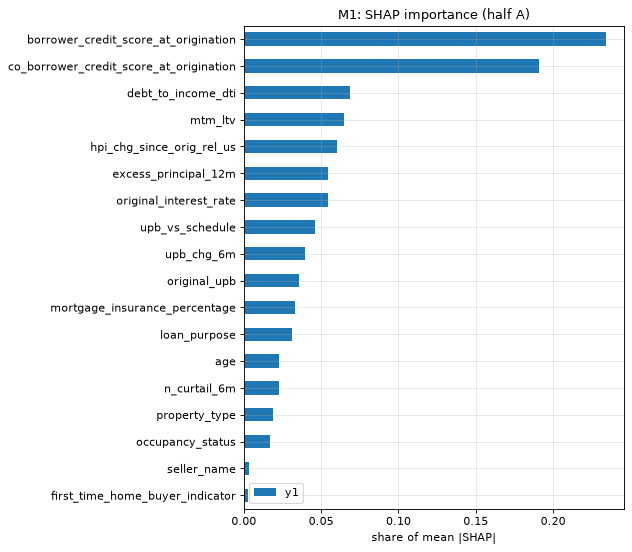

,y1
borrower_credit_score_at_origination,0.2341
co_borrower_credit_score_at_origination,0.1909
debt_to_income_dti,0.0683
mtm_ltv,0.0645
hpi_chg_since_orig_rel_us,0.0602
excess_principal_12m,0.0544
original_interest_rate,0.0542
upb_vs_schedule,0.0462
upb_chg_6m,0.0393
original_upb,0.0359


In [6]:
shap_rows = {}
for v in ["m1_y1"]:
    m = registry.meta(v)
    label = m["label"]
    va = load_eval("validation", label, m["features"], m["categorical"]).filter(pl.col("half") == "A")
    pos, neg = va.filter(pl.col(label) == 1), va.filter(pl.col(label) == 0)
    va = pl.concat([pos, neg.sample(n=30_000 - pos.height, seed=20261025)])
    enc = pickle.loads((MODELS_DIR / v / "encoder.pkl").read_bytes())
    pool = cb.pool(to_model_frame(va, m["features"], enc), cat_features=m["categorical"])
    sv = np.zeros((va.height, len(m["features"]) + 1))
    for k in range(cb.K_FOLDS):
        mk = CatBoostClassifier(); mk.load_model(str(MODELS_DIR / v / f"fold_{k}.cbm"))
        sv += mk.get_feature_importance(pool, type="ShapValues") / cb.K_FOLDS
    shap_rows[label] = pd.Series(np.abs(sv[:, :-1]).mean(axis=0), index=m["features"])
    del va, pool; gc.collect()
shap_imp = pd.DataFrame(shap_rows)
shap_imp = shap_imp.div(shap_imp.sum()).sort_values("y1", ascending=False)
shap_imp.to_csv(MODELING_DIR / "m1_shap_importance.csv")
fig, ax = plt.subplots(figsize=(8, 7))
shap_imp.iloc[::-1].plot.barh(ax=ax); ax.set_xlabel("share of mean |SHAP|"); ax.set_title("M1: SHAP importance (half A)")
plt.tight_layout(); plt.show()
shap_imp

**EN. How to read.** **Credit scores dominate:** borrower FICO 23.4 % and co-borrower FICO 19.1 % of the mean |SHAP| (a missing co-borrower score marks a single-borrower loan, which is riskier: 0.21 % vs 0.12 % on train). With DTI (6.8 %) and the first-time-buyer flag (0.3 %) the **borrower group gives 50 %**, in line with stage 2, where removing it cost 0.08 AUC. Next come the current MTM LTV (6.5 %), the house-price change relative to the US (6.0 %), the extra principal paid over 12 months (5.4 %), the interest rate (5.4 %), the balance against schedule (4.6 %) and the 6-month balance change (3.9 %). By group: borrower 49.6 %, behaviour 16.3 %, loan terms 15.8 %, macro 12.5 %, loan amount 3.6 %, loan age 2.3 %; the **dynamic features together give 31 %** — the part of the signal that changes while the loan is being paid on time. The weakest are `seller_name` and `first_time_home_buyer_indicator` (0.3 % each; the first-time-buyer flag was already the weakest in stage 2 and moves the B0 score by only 2.8 points). A large borrower share does not mean an inflated AUC: in stage 2 (02_9, section 4) the model without the borrower group was worse on every metric, including precision and recall, and inside each FICO band the AUC stayed 0.70–0.81. At the supervisor's request the AUC inside FICO bands is also reported for the final models on validation and test (03_4, 03_6).

**RU. Как читать.** **Доминируют кредитные рейтинги:** FICO заёмщика — 23,4 %, FICO созаёмщика — 19,1 % среднего |SHAP| (пропуск FICO созаёмщика означает кредит с одним заёмщиком, он рискованнее: 0,21 % против 0,12 % на train). Вместе с DTI (6,8 %) и флагом первой покупки (0,3 %) **группа заёмщика даёт 50 %**, что согласуется с этапом 2, где без неё AUC падал на 0,08. Далее — текущий MTM LTV (6,5 %), изменение цен на жильё относительно США (6,0 %), сверхплановое погашение за 12 мес. (5,4 %), ставка (5,4 %), остаток долга относительно графика (4,6 %) и изменение долга за 6 мес. (3,9 %). По группам: заёмщик 49,6 %, поведение 16,3 %, условия кредита 15,8 %, макро 12,5 %, сумма кредита 3,6 %, возраст кредита 2,3 %; **динамические признаки вместе дают 31 %** — та часть сигнала, которая меняется, пока кредит обслуживается вовремя. Слабее всех `seller_name` и `first_time_home_buyer_indicator` (по 0,3 %; флаг первой покупки был самым слабым уже на этапе 2 и сдвигает скор B0 всего на 2,8 балла). Большая доля группы заёмщика не означает завышенного AUC: на этапе 2 (02_9, раздел 4) модель без этой группы была хуже по всем метрикам, включая precision и recall, а внутри каждой группы FICO AUC оставался 0,70–0,81. По просьбе руководителя AUC внутри групп FICO сообщается и для итоговых моделей на validation и test (03_4, 03_6).